# Révision pandas — en local

**Objectif de la séance.** Reprendre ce que vous avez vu ces deux dernières semaines — charger, explorer, nettoyer, transformer, visualiser — mais cette fois **sur votre machine**, dans VS Code, avec votre environnement virtuel.

Rien de nouveau côté pandas. Ce qui change, c'est l'endroit où vous travaillez.

---

**Avant de commencer**

1. Votre dossier de projet est ouvert dans VS Code (*Fichier → Ouvrir le dossier…*).
2. Les quatre fichiers `.csv` sont dans le sous-dossier `data/`.
3. Votre environnement virtuel est créé, activé, et `pandas` y est installé :

```
python -m venv .venv
source .venv/Scripts/activate
pip install pandas matplotlib
```

4. En haut à droite de ce notebook, le noyau sélectionné est bien celui du `.venv`.

---

**Les données.** Quatre extraits de la base de la FAO (Organisation des Nations unies pour l'alimentation et l'agriculture) :

| Fichier | Contenu | Lignes |
|---|---|---|
| `population.csv` | population par pays et par année | 1 416 |
| `sous_nutrition.csv` | personnes en sous-nutrition, par période | 1 218 |
| `aide_alimentaire.csv` | aide reçue, par pays, année et produit | 1 475 |
| `dispo_alimentaire.csv` | disponibilité alimentaire par pays et produit | 15 605 |


## 0 — Vérifier son environnement

Le réflexe de la journée. Avant toute chose, on s'assure que le Python qui exécute ce notebook est bien celui du projet.

In [1]:
import sys
print(sys.executable)

c:\Users\helen\Documents\collecte\.venv\Scripts\python.exe


Le chemin doit **passer par votre dossier de projet** et contenir `.venv`.

S'il pointe vers `AppData` ou `anaconda3`, le noyau n'est pas le bon : cliquez sur le sélecteur de noyau, en haut à droite, et choisissez l'interpréteur du `.venv`.

In [2]:
import pandas as pd
print("pandas", pd.__version__)

pandas 3.1.0


---
## 1 — Charger les fichiers

Sur Colab, vous écriviez `/content/mon_fichier.csv`. Ce chemin n'existe plus.

Ici, on écrit un **chemin relatif** : il part du dossier ouvert dans VS Code. `data/population.csv` se lit « dans le sous-dossier `data`, le fichier `population.csv` ».

In [3]:
population = pd.read_csv("data/population.csv")
population.head()

,Zone,Année,Valeur
0,Afghanistan,2013,32269.589
1,Afghanistan,2014,33370.794
2,Afghanistan,2015,34413.603
3,Afghanistan,2016,35383.032
4,Afghanistan,2017,36296.113


### À vous

Chargez les trois autres fichiers dans `sous_nutrition`, `aide_alimentaire` et `dispo_alimentaire`.

In [ ]:
# Chargez les trois fichiers restants, sur le modele de population
# sous_nutrition, aide_alimentaire, dispo_alimentaire
sous_nut = pd.read_csv("data/sous_nutrition.csv")
sous_nut.head()

,Zone,Année,Valeur
0,Afghanistan,2012-2014,8.6
1,Afghanistan,2013-2015,8.8
2,Afghanistan,2014-2016,8.9
3,Afghanistan,2015-2017,9.7
4,Afghanistan,2016-2018,10.5


In [5]:
dispo_alim= pd.read_csv("data/dispo_alimentaire.csv")
dispo_alim.head()


,Zone,Produit,Origine,Aliments pour animaux,Autres Utilisations,Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité de matière grasse en quantité (g/personne/jour),Disponibilité de protéines en quantité (g/personne/jour),Disponibilité intérieure,Exportations - Quantité,Importations - Quantité,Nourriture,Pertes,Production,Semences,Traitement,Variation de stock
0,Afghanistan,Abats Comestible,animale,NaN,NaN,5.0,1.72,0.20,0.77,53.0,NaN,NaN,53.0,NaN,53.0,NaN,NaN,NaN
1,Afghanistan,"Agrumes, Autres",vegetale,NaN,NaN,1.0,1.29,0.01,0.02,41.0,2.0,40.0,39.0,2.0,3.0,NaN,NaN,NaN
2,Afghanistan,Aliments pour enfants,vegetale,NaN,NaN,1.0,0.06,0.01,0.03,2.0,NaN,2.0,2.0,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,Ananas,vegetale,NaN,NaN,0.0,0.00,NaN,NaN,0.0,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,Bananes,vegetale,NaN,NaN,4.0,2.70,0.02,0.05,82.0,NaN,82.0,82.0,NaN,NaN,NaN,NaN,NaN


In [6]:
aide_alim= pd.read_csv("data/aide_alimentaire.csv")
aide_alim.head()

,Pays bénéficiaire,Année,Produit,Valeur
0,Afghanistan,2013,Autres non-céréales,682
1,Afghanistan,2014,Autres non-céréales,335
2,Afghanistan,2013,Blé et Farin,39224
3,Afghanistan,2014,Blé et Farin,15160
4,Afghanistan,2013,Céréales,40504


> **Si vous obtenez `FileNotFoundError`** — le chemin est relatif au dossier **ouvert dans VS Code**, pas au dossier du notebook. Vérifiez avec les deux lignes ci-dessous.

In [ ]:
import os
print(os.getcwd())
print(os.listdir("data"))

---
## 2 — Explorer

Quatre questions à se poser devant n'importe quel fichier, toujours dans cet ordre :

1. Combien de lignes, combien de colonnes ? → `.shape`
2. Comment s'appellent les colonnes, de quel type sont-elles, combien de valeurs manquent ? → `.info()`
3. À quoi ressemble une ligne ? → `.head()`
4. Quelles valeurs prend une colonne qualitative ? → `.value_counts()`

In [ ]:
print("Dimensions :", population.shape)      #1416 lignes, 3 colonnes
population.info()                             #pas de null zone: type chaine de caractère, année: entier, valeur: décimaux
population.head()
population["Zone"].value_counts()     # chaque pays semble apparaitre 6x
population.describe()       #

Dimensions : (1416, 3)
<class 'pandas.DataFrame'>
RangeIndex: 1416 entries, 0 to 1415
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Zone    1416 non-null   str    
 1   Année   1416 non-null   int64  
 2   Valeur  1416 non-null   float64
dtypes: float64(1), int64(1), str(1)
memory usage: 33.3 KB


,Année,Valeur
count,1416.000000,1.416000e+03
mean,2015.500000,3.144793e+04
std,1.708428,1.300812e+05
min,2013.000000,7.930000e-01
25%,2014.000000,3.783410e+02
50%,2015.500000,5.126480e+03
75%,2017.000000,1.930666e+04
max,2018.000000,1.427648e+06


### À vous

Affichez les dimensions et les informations de `sous_nutrition`, puis ses cinq premières lignes.

**Regardez bien le type de la colonne `Valeur`, et le format de la colonne `Année`.** Les deux vont nous occuper dans la partie suivante.

In [ ]:
# Dimensions, informations, puis cinq premieres lignes de sous_nutrition
sous_nut.info()          # 3 colonnes de type chaîne de caractères, valeur a des null
sous_nut.shape            # 1218 lignes, 3 colonnes
sous_nut["Zone"].value_counts()       #des périodes dans année, valeurs: des décimaux, zone = pays, 6 occurences de chaque pays
sous_nut.head()
sous_nut["Valeur"].isna().sum()          #594 Nan dans valeur
sous_nut["Année"].value_counts()
sous_nut.describe()                  #203 pays différents


<class 'pandas.DataFrame'>
RangeIndex: 1218 entries, 0 to 1217
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Zone    1218 non-null   str  
 1   Année   1218 non-null   str  
 2   Valeur  624 non-null    str  
dtypes: str(3)
memory usage: 28.7 KB


,Zone,Année,Valeur
count,1218,1218,624
unique,203,6,139
top,Afghanistan,2012-2014,<0.1
freq,6,203,120


### À vous

`dispo_alimentaire` contient une colonne `Origine`. Combien de produits d'origine végétale, combien d'origine animale ?

In [46]:
# Combien de produits d'origine vegetale, combien d'origine animale ?
dispo_alim.shape       # 15605 lignes, 18 colonnes
dispo_alim.info()      # zone, produit, origine: str pas de null, autres colonnes: float et des null
dispo_alim.head()
dispo_alim.describe()    # des nombres négatifs
dispo_alim["Origine"].value_counts()      # 11896 d'origine végétal, 3709 d'origine animale
dispo_alim["Produit"].value_counts()

<class 'pandas.DataFrame'>
RangeIndex: 15605 entries, 0 to 15604
Data columns (total 18 columns):
 #   Column                                                         Non-Null Count  Dtype  
---  ------                                                         --------------  -----  
 0   Zone                                                           15605 non-null  str    
 1   Produit                                                        15605 non-null  str    
 2   Origine                                                        15605 non-null  str    
 3   Aliments pour animaux                                          2720 non-null   float64
 4   Autres Utilisations                                            5496 non-null   float64
 5   Disponibilité alimentaire (Kcal/personne/jour)                 14241 non-null  float64
 6   Disponibilité alimentaire en quantité (kg/personne/an)         14015 non-null  float64
 7   Disponibilité de matière grasse en quantité (g/personne/jour)  11794 

Produit
Abats Comestible          174
Beurre, Ghee              174
Bière                     174
Blé                       174
Boissons Alcooliques      174
                         ... 
Sucre, betterave          107
Ignames                    80
Sucre non centrifugé       30
Huile de Son de Riz        21
Viande de Anim Aquatiq      3
Name: count, Length: 98, dtype: int64

---
## 3 — Nettoyer

Trois problèmes classiques, tous les trois présents dans ces fichiers.

### 3.1 — Une colonne numérique stockée en texte

`sous_nutrition["Valeur"]` est de type `object`, c'est-à-dire du texte. La raison : certaines lignes contiennent `<0.1` au lieu d'un nombre.

`pd.to_numeric` convertit. Son argument `errors="coerce"` dit : *ce que tu ne sais pas convertir, remplace-le par `NaN` au lieu de planter*.

In [47]:
print("Type de la colonne :", sous_nut["Valeur"].dtype)

# Quelles valeurs pandas n'arrive-t-il pas a lire comme des nombres ?
suspectes = pd.to_numeric(sous_nut["Valeur"], errors="coerce").isna() & sous_nut["Valeur"].notna()
print(sous_nut.loc[suspectes, "Valeur"].value_counts())

Type de la colonne : str
Valeur
<0.1    120
Name: count, dtype: int64


In [48]:
sous_nut["Valeur"] = pd.to_numeric(sous_nut["Valeur"], errors="coerce")
print("Après :", sous_nut["Valeur"].dtype)
print("Valeurs manquantes :", sous_nut["Valeur"].isna().sum(), "sur", len(sous_nut))

Après : float64
Valeurs manquantes : 714 sur 1218


714 valeurs manquantes sur 1 218 — mais elles ne viennent pas toutes du même endroit :

- **594** cellules étaient déjà vides dans le fichier : la FAO ne publie pas d'estimation pour ces pays.
- **120** contenaient `<0.1`, ce qui veut dire *moins de cent mille personnes*. Ce n'est pas une donnée manquante, c'est une donnée imprécise — et `coerce` vient de les confondre.

Retenez le principe : `errors="coerce"` vous évite un plantage, il ne vous dispense pas de regarder ce qu'il a transformé. Dans une vraie étude, on remplacerait `<0.1` par `0.05` plutôt que de le perdre.

**Et attention au réflexe `fillna(0)`.** Remplacer les 594 par zéro reviendrait à affirmer qu'il n'y a aucune personne en sous-nutrition dans ces pays. C'est faux : on ne sait pas. Ici, la bonne décision est de les **écarter** au moment du calcul, pas de les remplir.

### 3.2 — Des noms de colonnes incohérents

`aide_alimentaire` appelle le pays `Pays bénéficiaire`, les trois autres fichiers l'appellent `Zone`. Impossible de faire une jointure comme ça.

In [50]:
aide_alim = aide_alim.rename(columns={"Pays bénéficiaire": "Zone"})
aide_alim.head(3)

,Zone,Année,Produit,Valeur
0,Afghanistan,2013,Autres non-céréales,682
1,Afghanistan,2014,Autres non-céréales,335
2,Afghanistan,2013,Blé et Farin,39224


### 3.3 — Des unités à harmoniser

Chaque fichier a la sienne :

| Table | Colonne | Unité d'origine |
|---|---|---|
| `population` | `Valeur` | milliers d'habitants |
| `sous_nutrition` | `Valeur` | millions de personnes |
| `aide_alimentaire` | `Valeur` | tonnes |

### À vous

Dans `population`, créez une colonne `Population` qui contient le nombre réel d'habitants, puis affichez les cinq premières lignes pour vérifier.

In [57]:
# Creez la colonne Population, puis affichez les cinq premieres lignes
population.head()
population["Population"] = (population["Valeur"]*1000).astype(int)
population.head()


,Zone,Année,Valeur,Population
0,Afghanistan,2013,32269.589,32269589
1,Afghanistan,2014,33370.794,33370794
2,Afghanistan,2015,34413.603,34413603
3,Afghanistan,2016,35383.032,35383032
4,Afghanistan,2017,36296.113,36296113


---
## 4 — Transformer

### 4.1 — Découper une colonne texte

La colonne `Année` de `sous_nutrition` ne contient pas une année mais une **période** : `2016-2018`. La FAO lisse ses estimations sur trois ans.

Pour filtrer dessus, on la découpe avec les méthodes `.str` — celles que vous avez vues la semaine dernière.

In [58]:
sous_nut["Annee_debut"] = sous_nut["Année"].str.split("-").str[0].astype(int)
sous_nut["Annee_fin"]   = sous_nut["Année"].str.split("-").str[1].astype(int)
sous_nut[["Zone", "Année", "Annee_debut", "Annee_fin", "Valeur"]].head()

,Zone,Année,Annee_debut,Annee_fin,Valeur
0,Afghanistan,2012-2014,2012,2014,8.6
1,Afghanistan,2013-2015,2013,2015,8.8
2,Afghanistan,2014-2016,2014,2016,8.9
3,Afghanistan,2015-2017,2015,2017,9.7
4,Afghanistan,2016-2018,2016,2018,10.5


### 4.2 — Filtrer

On va travailler sur la période `2016-2018`, centrée sur 2017, et écarter les pays sans chiffre.

In [69]:
sn_2017 = sous_nut[sous_nut["Année"] == "2016-2018"].dropna(subset=["Valeur"]).copy()
print(len(sn_2017), "pays avec une estimation")
sn_2017.head()

84 pays avec une estimation


,Zone,Année,Valeur,Annee_debut,Annee_fin
4,Afghanistan,2016-2018,10.5,2016,2018
10,Afrique du Sud,2016-2018,3.1,2016,2018
16,Albanie,2016-2018,0.1,2016,2018
22,Algérie,2016-2018,1.3,2016,2018
40,Angola,2016-2018,5.8,2016,2018


### À vous

Créez `pop_2017` : les lignes de `population` pour l'année 2017.

In [60]:
population.head()

,Zone,Année,Valeur,Population
0,Afghanistan,2013,32269.589,32269589
1,Afghanistan,2014,33370.794,33370794
2,Afghanistan,2015,34413.603,34413603
3,Afghanistan,2016,35383.032,35383032
4,Afghanistan,2017,36296.113,36296113


In [67]:
# Creez pop_2017 : les lignes de population pour l'annee 2017
pop_2017=population[population["Année"] ==2017]
print(len(pop_2017))
pop_2017.head()

236


,Zone,Année,Valeur,Population
4,Afghanistan,2017,36296.113,36296113
10,Afrique du Sud,2017,57009.756,57009756
16,Albanie,2017,2884.169,2884169
22,Algérie,2017,41389.189,41389189
28,Allemagne,2017,82658.409,82658409


### 4.3 — Joindre

`merge` rapproche deux tables sur une colonne commune. `how="inner"` ne garde que les pays présents des deux côtés.

In [68]:
etude = sn_2017.merge(pop_2017[["Zone", "Population"]], on="Zone", how="inner")
print(etude.shape)
etude.head(3)

(84, 6)


,Zone,Année,Valeur,Annee_debut,Annee_fin,Population
0,Afghanistan,2016-2018,10.5,2016,2018,36296113
1,Afrique du Sud,2016-2018,3.1,2016,2018,57009756
2,Albanie,2016-2018,0.1,2016,2018,2884169


### 4.4 — Calculer

### À vous

Dans `etude`, créez deux colonnes :

- `Sous_nutrition` : le nombre de personnes (la colonne `Valeur` est en **millions**)
- `Proportion` : la part de la population du pays, **en pourcentage**

Puis affichez les dix pays où cette proportion est la plus forte, avec `nlargest`.

In [79]:
# Creez les colonnes Sous_nutrition et Proportion, puis affichez le top 10
etude["Sous_nutrition"]= (etude["Valeur"]*1000000).astype(int)
#etude.head()
etude["Proportion"]= round(((etude["Sous_nutrition"]*100)/etude["Population"]),2)
etude.head()
etude.nlargest(10,"Proportion")


,Zone,Année,Valeur,Annee_debut,Annee_fin,Population,Sous_nutrition,Proportion
32,Haïti,2016-2018,5.3,2016,2018,10982366,5300000,48.26
67,République populaire démocratique de Corée,2016-2018,12.0,2016,2018,25429825,12000000,47.19
45,Madagascar,2016-2018,10.5,2016,2018,25570512,10500000,41.06
44,Libéria,2016-2018,1.8,2016,2018,4702226,1800000,38.28
42,Lesotho,2016-2018,0.8,2016,2018,2091534,800000,38.25
76,Tchad,2016-2018,5.7,2016,2018,15016753,5700000,37.96
69,Rwanda,2016-2018,4.2,2016,2018,11980961,4200000,35.06
53,Mozambique,2016-2018,9.4,2016,2018,28649018,9400000,32.81
78,Timor-Leste,2016-2018,0.4,2016,2018,1243258,400000,32.17
0,Afghanistan,2016-2018,10.5,2016,2018,36296113,10500000,28.93


Haïti en tête, à 48,3 %. Près d'un habitant sur deux.

### 4.5 — Agréger

`groupby` regroupe les lignes qui partagent une valeur, puis applique un calcul à chaque groupe.

`aide_alimentaire` a une ligne par pays, par année **et par produit**. Pour obtenir le total reçu par pays, on regroupe sur `Zone` et on somme.

In [80]:
aide_alim.head()

,Zone,Année,Produit,Valeur
0,Afghanistan,2013,Autres non-céréales,682
1,Afghanistan,2014,Autres non-céréales,335
2,Afghanistan,2013,Blé et Farin,39224
3,Afghanistan,2014,Blé et Farin,15160
4,Afghanistan,2013,Céréales,40504


In [81]:
aide_par_pays = aide_alim.groupby("Zone")["Valeur"].sum().sort_values(ascending=False)
aide_par_pays.head(10)

Zone
République arabe syrienne           1858943
Éthiopie                            1381294
Yémen                               1206484
Soudan du Sud                        695248
Soudan                               669784
Kenya                                552836
Bangladesh                           348188
Somalie                              292678
République démocratique du Congo     288502
Niger                                276344
Name: Valeur, dtype: int64

### À vous

`dispo_alimentaire` a une ligne par pays **et par produit**. Calculez la disponibilité totale en kcal par personne et par jour pour chaque pays, à partir de la colonne `Disponibilité alimentaire (Kcal/personne/jour)`.

Affichez ensuite les cinq pays les moins bien dotés, avec `nsmallest`.

In [82]:
dispo_alim.head()

,Zone,Produit,Origine,Aliments pour animaux,Autres Utilisations,Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité de matière grasse en quantité (g/personne/jour),Disponibilité de protéines en quantité (g/personne/jour),Disponibilité intérieure,Exportations - Quantité,Importations - Quantité,Nourriture,Pertes,Production,Semences,Traitement,Variation de stock
0,Afghanistan,Abats Comestible,animale,NaN,NaN,5.0,1.72,0.20,0.77,53.0,NaN,NaN,53.0,NaN,53.0,NaN,NaN,NaN
1,Afghanistan,"Agrumes, Autres",vegetale,NaN,NaN,1.0,1.29,0.01,0.02,41.0,2.0,40.0,39.0,2.0,3.0,NaN,NaN,NaN
2,Afghanistan,Aliments pour enfants,vegetale,NaN,NaN,1.0,0.06,0.01,0.03,2.0,NaN,2.0,2.0,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,Ananas,vegetale,NaN,NaN,0.0,0.00,NaN,NaN,0.0,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,Bananes,vegetale,NaN,NaN,4.0,2.70,0.02,0.05,82.0,NaN,82.0,82.0,NaN,NaN,NaN,NaN,NaN


In [88]:
# Disponibilite totale par pays, puis les cinq plus faibles
dispo_totale= dispo_alim.groupby("Zone")["Disponibilité alimentaire (Kcal/personne/jour)"].sum().sort_values(ascending= True)
dispo_totale.head()
dispo_totale.nsmallest(5)



Zone
République centrafricaine    1879.0
Zambie                       1924.0
Madagascar                   2056.0
Afghanistan                  2087.0
Haïti                        2089.0
Name: Disponibilité alimentaire (Kcal/personne/jour), dtype: float64

In [89]:
dispo_totale.nsmallest(5)

Zone
République centrafricaine    1879.0
Zambie                       1924.0
Madagascar                   2056.0
Afghanistan                  2087.0
Haïti                        2089.0
Name: Disponibilité alimentaire (Kcal/personne/jour), dtype: float64

> Pour information, le besoin moyen d'un adulte est de l'ordre de 2 000 à 2 500 kcal par jour.

---
## 5 — Visualiser

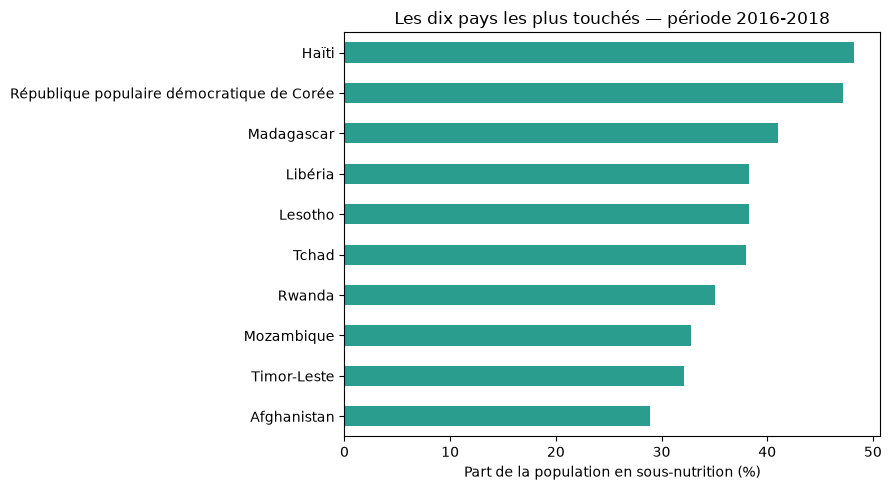

In [90]:
import matplotlib.pyplot as plt

top10 = etude.nlargest(10, "Proportion").sort_values("Proportion")

ax = top10.plot(x="Zone", y="Proportion", kind="barh", figsize=(9, 5), legend=False, color="#2A9D8F")
ax.set_xlabel("Part de la population en sous-nutrition (%)")
ax.set_ylabel("")
ax.set_title("Les dix pays les plus touchés — période 2016-2018")
plt.tight_layout()
plt.show()

### À vous

Faites le même graphique pour les dix pays qui ont reçu le plus d'aide alimentaire, à partir de `aide_par_pays`.

*Indice : `aide_par_pays` est une Series. `.head(10)` donne les dix premières, `.sort_values()` les remet dans l'ordre croissant pour l'affichage.*

In [94]:
# Le meme graphique, pour les dix premiers beneficiaires de l'aide
pays10= aide_par_pays.head(10).sort_values(ascending=False)
pays10

Zone
République arabe syrienne           1858943
Éthiopie                            1381294
Yémen                               1206484
Soudan du Sud                        695248
Soudan                               669784
Kenya                                552836
Bangladesh                           348188
Somalie                              292678
République démocratique du Congo     288502
Niger                                276344
Name: Valeur, dtype: int64

---
## 6 — Exporter

Un résultat qui reste dans un notebook n'est pas un livrable. On l'écrit sur le disque, dans `data/`.

In [ ]:
resultat = etude[["Zone", "Population", "Sous_nutrition", "Proportion"]].sort_values("Proportion", ascending=False)
resultat.to_csv("data/sous_nutrition_2017.csv", index=False)
print(len(resultat), "lignes écrites dans data/sous_nutrition_2017.csv")

Regardez l'explorateur de VS Code, à gauche : le fichier est apparu dans `data/`.

C'est une différence de fond avec Colab. Ce fichier est **sur votre machine**, il survivra à la fermeture de VS Code, et il pourra être versionné.

---

## Pour aller plus loin

Si vous avez terminé, trois questions sans guide :

1. Combien de personnes en sous-nutrition dans le monde sur la période 2016-2018 ? Quelle part de la population mondiale ?
2. Quels sont les dix pays où la disponibilité alimentaire par personne est la plus **élevée** ?
3. Pour les cinq premiers bénéficiaires de l'aide alimentaire, comment le montant reçu évolue-t-il entre 2013 et 2016 ? (`groupby` sur deux colonnes, puis `unstack`)
